# 04 Model Comparison: Decision Tree and Random Forest

**IDX Exchange Data Science Internship, Week 5 deliverable**

**Goal.** Train a decision tree and a random forest to predict `ClosePrice`, compare them with the Week 4 linear regression baseline on the test month, and document how each model behaves: its strengths and its weaknesses.

**Same setup as Week 4**, so that the comparison is fair:
- the same cleaned data, inputs and preprocessor (from Week 3);
- the same 12-month training windows: settings are chosen by training on March 2025 to February 2026 and scoring the **validation month**, March 2026; the final models are trained on April 2025 to March 2026 and scored once on the **test month**, April 2026;
- every model predicts the logarithm of the price, which Week 4 found works much better than predicting dollars;
- the same four measures, each built from a home's percentage error |predicted − actual| / actual: **MdAPE** (median percentage error, the headline), **MAPE** (mean percentage error), **R²** (share of the variation in prices explained) and **MAE** (mean error in dollars).

**The bar to beat** (Week 4, test month): R² 0.820, MdAPE 11.38%. Over four months the baseline's MdAPE varied by 0.55 percentage points, so a convincing improvement must be clearly larger than that.

**Contents**
1. Load the data and the baseline results
2. Decision tree: how it works and choosing its settings
3. Random forest: how it works and choosing its settings
4. Final fit and the test month
5. Is the improvement real?
6. Where the improvement comes from
7. What the random forest relies on
8. Strengths and weaknesses
9. Saved results
10. Summary and next steps

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer
from sklearn.tree import DecisionTreeRegressor

ROOT = next(p for p in [Path('..'), Path('.')] if (p / 'src' / 'preprocessing.py').exists()).resolve()
sys.path.insert(0, str(ROOT))
import src.preprocessing as prep
import src.modeling as mdl

SEED = prep.set_global_seed()
print('Random seed:', SEED)

CONFIG = json.loads((ROOT / 'config' / 'split_config.json').read_text())
RESULTS_DIR = ROOT / 'results'
FIG_DIR = ROOT / 'reports' / 'figures'

# One color per model, used in every chart
COLORS = {'Linear regression': '#2a78d6', 'Decision tree': '#eb6834', 'Random forest': '#1baf7a'}
GRAY, LIGHT_GRAY = '#a3a29d', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': LIGHT_GRAY, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9.5,
})
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')


def money(x, _=None):
    return f'${x / 1e6:.1f}M' if abs(x) >= 1e6 else f'${x / 1e3:.0f}K'


def show_metrics(m):
    return {'R2': f"{m['R2']:.3f}", 'MAPE': f"{m['MAPE']:.2f}%", 'MdAPE': f"{m['MdAPE']:.2f}%",
            'MAE': f"${m['MAE']:,.0f}"}

Random seed: 42


## 1. Load the data and the baseline results

The splits are rebuilt exactly as in Weeks 3 and 4 and checked against the saved row counts. The baseline's recorded scores are read from `results/03_baseline_metrics.csv`.

In [2]:
clean_df = prep.load_clean(ROOT / 'data' / 'processed' / 'sfr_clean.csv')
N_MONTHS = CONFIG['n_train_months']
TEST_MONTH = CONFIG['final']['test_month']
VALIDATION_MONTH = CONFIG['tuning']['validation_month']

train_tune, val_tune, _ = prep.make_split(clean_df, VALIDATION_MONTH, N_MONTHS)
train_final, test_final, _ = prep.make_split(clean_df, TEST_MONTH, N_MONTHS)
assert len(train_final) == CONFIG['final']['train_rows'] and len(test_final) == CONFIG['final']['test_rows']

baseline_results = pd.read_csv(RESULTS_DIR / '03_baseline_metrics.csv')
print(f'Settings split: train {len(train_tune):,}, validate {len(val_tune):,} ({VALIDATION_MONTH})')
print(f'Final split:    train {len(train_final):,}, test {len(test_final):,} ({TEST_MONTH})')
baseline_results[['evaluation', 'eval_month', 'R2', 'MdAPE']]

Settings split: train 127,358, validate 11,354 (2026-03)
Final split:    train 128,330, test 12,268 (2026-04)


,evaluation,eval_month,R2,MdAPE
0,validation (choosing settings),2026-03,0.82,11.40
1,earlier month (stability),2025-04,0.84,10.83
2,earlier month (stability),2025-07,0.85,11.00
3,earlier month (stability),2025-10,0.84,11.16
4,test (final result),2026-04,0.82,11.38


## 2. Decision tree

**How it works.** A decision tree predicts by asking a sequence of yes/no questions about the inputs, such as "is the ZIP-code price level above x?" and then "is the living area above y?". Each question splits the training homes into two groups, chosen so that log prices within each group are as similar as possible. Splitting stops at a maximum depth or when a group would become too small. Each final group is called a *leaf*, and a new home is predicted by the average log price of the training homes in the leaf it lands in.

**Settings to choose.** Two settings control how detailed the tree gets:
- **Maximum depth:** the largest number of questions on any path from the top of the tree to a leaf.
- **Minimum leaf size:** the fewest training homes allowed in a leaf.

A deeper tree with smaller leaves can follow the training data more closely, but it may start to memorize individual homes instead of general patterns (*overfitting*). Every combination below is trained on the settings split and scored on the validation month.

In [3]:
DT_DEPTHS = [4, 6, 8, 10, 12, 14, 16, 20, None]
DT_LEAVES = [1, 5, 10, 20, 50, 100]

dt_rows = []
for depth in DT_DEPTHS:
    for leaf in DT_LEAVES:
        model = mdl.price_model(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=SEED))
        model.fit(train_tune[prep.FEATURES], train_tune[prep.TARGET])
        m = prep.regression_metrics(val_tune[prep.TARGET], model.predict(val_tune[prep.FEATURES]))
        dt_rows.append({'max_depth': 'none' if depth is None else depth, 'min_samples_leaf': leaf, **m})
dt_grid = pd.DataFrame(dt_rows)
dt_best = dt_grid.loc[dt_grid['MdAPE'].idxmin()]
print(f"Best decision tree on the validation month: max_depth = {dt_best['max_depth']}, "
      f"min_samples_leaf = {dt_best['min_samples_leaf']}, MdAPE = {dt_best['MdAPE']:.2f}%")

Best decision tree on the validation month: max_depth = 20, min_samples_leaf = 10, MdAPE = 9.55%


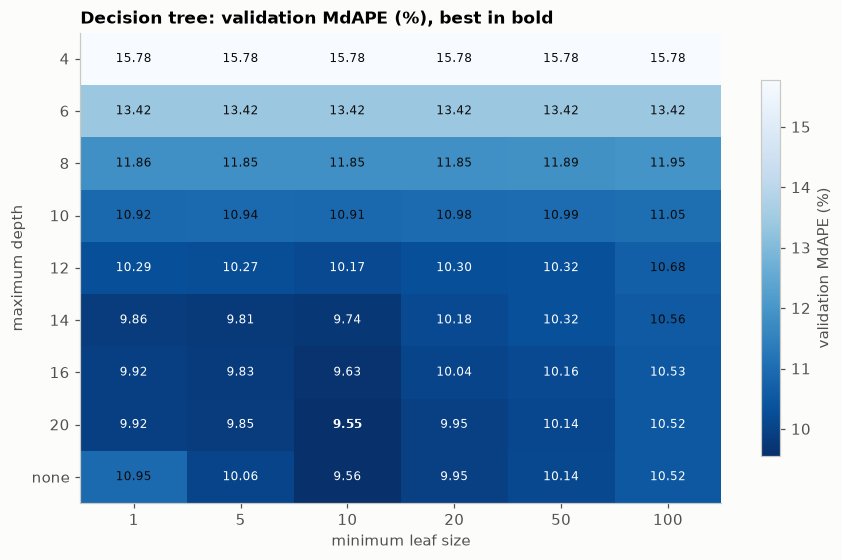

In [4]:
def grid_heatmap(grid, rows, cols, row_label, col_label, title, name):
    table = grid.pivot(index=rows, columns=cols, values='MdAPE')
    table = table.reindex(index=[r for r in grid[rows].unique()], columns=sorted(grid[cols].unique()))
    fig, ax = plt.subplots(figsize=(1.0 * table.shape[1] + 2.2, 0.42 * table.shape[0] + 1.4))
    im = ax.imshow(table.to_numpy(), cmap='Blues_r', aspect='auto')
    best = np.unravel_index(np.nanargmin(table.to_numpy()), table.shape)
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='#0b0b0b' if v > np.nanmedian(table.to_numpy()) else '#ffffff',
                fontweight='bold' if (i, j) == best else 'normal')
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel(col_label)
    ax.set_ylabel(row_label)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label='validation MdAPE (%)', shrink=0.8)
    plt.tight_layout()
    save_fig(name)
    plt.show()


grid_heatmap(dt_grid, 'max_depth', 'min_samples_leaf', 'maximum depth', 'minimum leaf size',
             'Decision tree: validation MdAPE (%), best in bold', '04_dt_tuning')

Very shallow trees are too coarse (a depth-4 tree has at most 16 leaves, so at most 16 different predicted prices), and very deep trees with tiny leaves overfit. The best trees sit in between. The chosen setting is the one with the lowest validation MdAPE.

## 3. Random forest

**How it works.** A random forest trains many decision trees and averages their predictions. Two sources of randomness make the trees differ from one another: each tree is trained on a *bootstrap sample* of the training homes (a sample of the same size drawn with replacement, so some homes appear several times and others not at all), and at each split only a random subset of the input columns is considered. A single deep tree reacts strongly to the particular homes it was trained on; averaging many such trees cancels much of that sensitivity while keeping their detail.

**Settings to choose.**
- **Share of input columns considered at each split** (`max_features`): smaller shares make the trees more different from one another.
- **Minimum leaf size**, as for the single tree. Forest trees are usually grown deep, because averaging removes most of the overfitting.
- **Number of trees:** more trees give a more stable average but take longer; it is set to 300 for the search below and examined separately afterwards.

In [5]:
RF_MAX_FEATURES = [0.2, 0.33, 0.5, 0.75, 1.0]
RF_LEAVES = [1, 2, 5, 10]
RF_TREES = 300


def make_forest(max_features, leaf, n_trees=RF_TREES):
    return RandomForestRegressor(n_estimators=n_trees, max_features=max_features, min_samples_leaf=leaf,
                                 n_jobs=-1, random_state=SEED)


rf_rows = []
start = time.time()
for mf in RF_MAX_FEATURES:
    for leaf in RF_LEAVES:
        model = mdl.price_model(make_forest(mf, leaf))
        model.fit(train_tune[prep.FEATURES], train_tune[prep.TARGET])
        m = prep.regression_metrics(val_tune[prep.TARGET], model.predict(val_tune[prep.FEATURES]))
        rf_rows.append({'max_features': mf, 'min_samples_leaf': leaf, **m})
rf_grid = pd.DataFrame(rf_rows)
rf_best = rf_grid.loc[rf_grid['MdAPE'].idxmin()]
print(f'{len(rf_grid)} forests in {time.time() - start:.0f} s')
print(f"Best random forest on the validation month: max_features = {rf_best['max_features']}, "
      f"min_samples_leaf = {int(rf_best['min_samples_leaf'])}, MdAPE = {rf_best['MdAPE']:.2f}%")

20 forests in 155 s
Best random forest on the validation month: max_features = 0.33, min_samples_leaf = 1, MdAPE = 7.68%


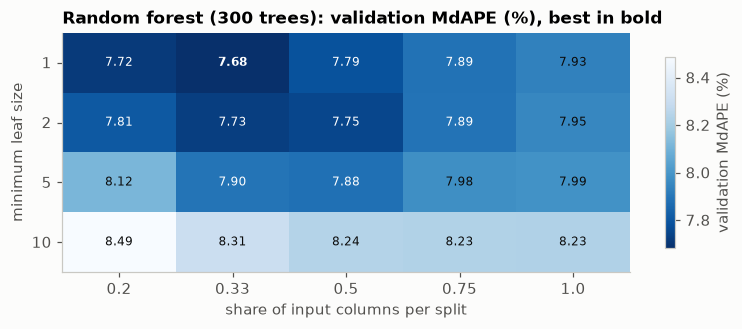

In [6]:
grid_heatmap(rf_grid, 'min_samples_leaf', 'max_features', 'minimum leaf size', 'share of input columns per split',
             'Random forest (300 trees): validation MdAPE (%), best in bold', '04_rf_tuning')

**Number of trees.** With the best two settings fixed, the forest is trained with different numbers of trees to check that 300 is enough.

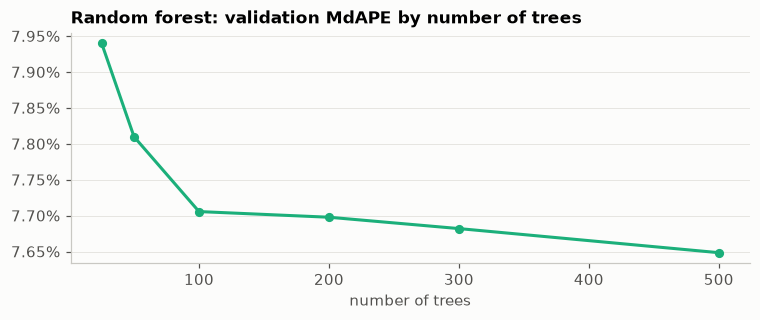

,trees,MdAPE,R2,fit_seconds
0,25,7.94,0.89,1.10
1,50,7.81,0.89,1.50
2,100,7.71,0.89,2.50
3,200,7.70,0.89,4.40
4,300,7.68,0.89,6.50
5,500,7.65,0.89,10.40


In [7]:
TREE_COUNTS = [25, 50, 100, 200, 300, 500]
best_mf, best_leaf = float(rf_best['max_features']), int(rf_best['min_samples_leaf'])
tree_rows = []
for n in TREE_COUNTS:
    start = time.time()
    model = mdl.price_model(make_forest(best_mf, best_leaf, n_trees=n))
    model.fit(train_tune[prep.FEATURES], train_tune[prep.TARGET])
    m = prep.regression_metrics(val_tune[prep.TARGET], model.predict(val_tune[prep.FEATURES]))
    tree_rows.append({'trees': n, 'MdAPE': m['MdAPE'], 'R2': m['R2'], 'fit_seconds': time.time() - start})
tree_curve = pd.DataFrame(tree_rows)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(tree_curve['trees'], tree_curve['MdAPE'], color=COLORS['Random forest'], lw=2, marker='o', ms=5)
ax.set_xlabel('number of trees')
ax.set_title('Random forest: validation MdAPE by number of trees')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.2f}%'))
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig('04_rf_trees')
plt.show()
tree_curve.round({'MdAPE': 3, 'R2': 4, 'fit_seconds': 1})

In [8]:
N_TREES = 300
gain_beyond = tree_curve.set_index('trees').loc[300, 'MdAPE'] - tree_curve.set_index('trees').loc[500, 'MdAPE']
print(f'Going from 300 to 500 trees changes validation MdAPE by {gain_beyond:+.3f} points; the forest keeps {N_TREES} trees.')

DT_SETTINGS = {'max_depth': None if dt_best['max_depth'] == 'none' else int(dt_best['max_depth']),
               'min_samples_leaf': int(dt_best['min_samples_leaf'])}
RF_SETTINGS = {'max_features': best_mf, 'min_samples_leaf': best_leaf, 'n_estimators': N_TREES}
MODELS = {
    'Linear regression': lambda: LinearRegression(),
    'Decision tree': lambda: DecisionTreeRegressor(**DT_SETTINGS, random_state=SEED),
    'Random forest': lambda: RandomForestRegressor(**RF_SETTINGS, n_jobs=-1, random_state=SEED),
}
print('Decision tree settings:', DT_SETTINGS)
print('Random forest settings:', RF_SETTINGS)

Going from 300 to 500 trees changes validation MdAPE by +0.034 points; the forest keeps 300 trees.
Decision tree settings: {'max_depth': 20, 'min_samples_leaf': 10}
Random forest settings: {'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 300}


## 4. Final fit and the test month

Each model is trained with its chosen settings on April 2025 to March 2026 and scored once on April 2026. The linear regression is refit here (it is deterministic, so its numbers equal the Week 4 record) because its per-home predictions are needed in the next sections. Training-set scores are shown to measure overfitting: the gap between how well a model fits its own training homes and how well it predicts new ones.

In [9]:
final_models, test_preds, rows = {}, {}, []
for name, make in MODELS.items():
    start = time.time()
    model = mdl.price_model(make()).fit(train_final[prep.FEATURES], train_final[prep.TARGET])
    fit_s = time.time() - start
    final_models[name] = model
    test_preds[name] = model.predict(test_final[prep.FEATURES])
    test_m = prep.regression_metrics(test_final[prep.TARGET], test_preds[name])
    train_m = prep.regression_metrics(train_final[prep.TARGET], model.predict(train_final[prep.FEATURES]))
    rows.append({'model': name, **test_m, 'train_MdAPE': train_m['MdAPE'], 'fit_seconds': fit_s})
final = pd.DataFrame(rows).set_index('model')

baseline_test = baseline_results.loc[baseline_results['eval_month'] == TEST_MONTH].iloc[0]
assert np.isclose(final.loc['Linear regression', 'MdAPE'], baseline_test['MdAPE'])

view = pd.DataFrame({n: show_metrics(final.loc[n]) for n in final.index}).T
view['MdAPE on training homes'] = [f'{v:.2f}%' for v in final['train_MdAPE']]
view['fit time'] = [f'{v:.1f} s' for v in final['fit_seconds']]
view

,R2,MAPE,MdAPE,MAE,MdAPE on training homes,fit time
Linear regression,0.820,15.17%,11.38%,"$207,051",11.16%,0.6 s
Decision tree,0.844,14.19%,9.81%,"$194,300",7.39%,1.1 s
Random forest,0.885,11.42%,7.76%,"$159,355",3.34%,6.1 s


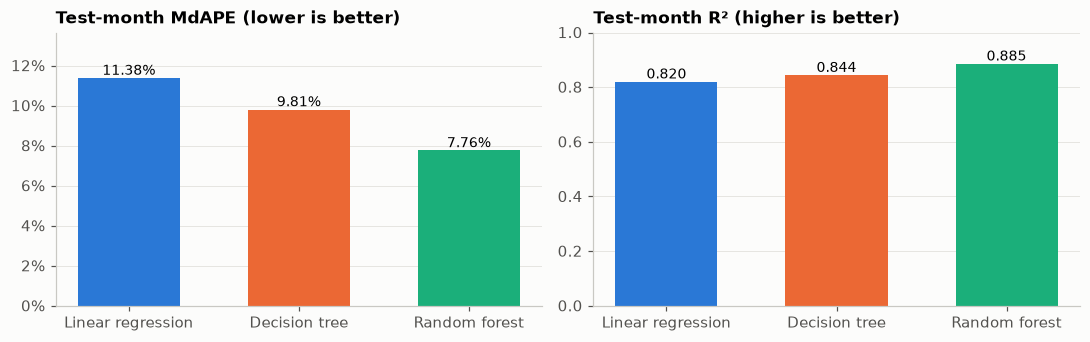

,within 5%,within 10%,within 20%
Linear regression,23.6%,44.7%,74.5%
Decision tree,28.3%,50.7%,77.5%
Random forest,35.1%,59.8%,84.0%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
names = list(final.index)
for ax, col, fmt, title in [(axes[0], 'MdAPE', lambda v: f'{v:.2f}%', 'Test-month MdAPE (lower is better)'),
                            (axes[1], 'R2', lambda v: f'{v:.3f}', 'Test-month R² (higher is better)')]:
    ax.bar(names, final[col], color=[COLORS[n] for n in names], width=0.6)
    for i, v in enumerate(final[col]):
        ax.text(i, v, fmt(v), ha='center', va='bottom', fontsize=9)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].set_ylim(0, final['MdAPE'].max() * 1.2)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].set_ylim(0, 1)
plt.tight_layout()
save_fig('04_test_comparison')
plt.show()

within = {n: 100 * np.abs(p - test_final[prep.TARGET].to_numpy()) / test_final[prep.TARGET].to_numpy()
          for n, p in test_preds.items()}
pd.DataFrame({n: {f'within {k}%': f'{(w <= k).mean():.1%}' for k in (5, 10, 20)} for n, w in within.items()}).T

## 5. Is the improvement real?

Two checks, following the best-practices requirement that an improvement be clearly larger than noise.

**Check 1: the same comparison at earlier months.** As in Week 4, each model is retrained on the 12 months before April, July and October 2025 and scored on that month, with the settings chosen above.

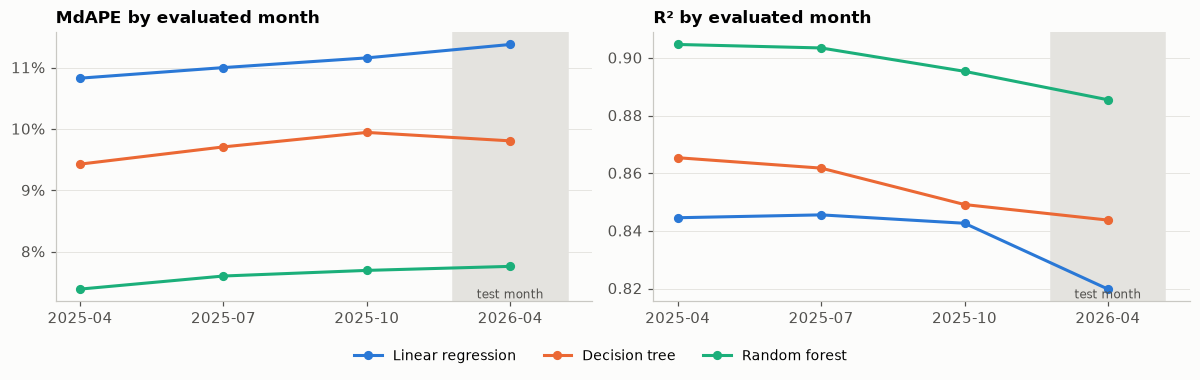

model,Linear regression,Decision tree,Random forest
eval_month,,,
2025-04,10.83,9.43,7.39
2025-07,11.00,9.71,7.60
2025-10,11.16,9.94,7.69
2026-04,11.38,9.81,7.76


In [11]:
BACKTEST_MONTHS = ['2025-04', '2025-07', '2025-10', TEST_MONTH]
bt_rows = []
for name, make in MODELS.items():
    for month in BACKTEST_MONTHS:
        bt_rows.append({'model': name, **mdl.fit_and_score(clean_df, month, N_MONTHS, make)[3]})
backtest = pd.DataFrame(bt_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, title in [(axes[0], 'MdAPE', 'MdAPE by evaluated month'), (axes[1], 'R2', 'R² by evaluated month')]:
    for name in MODELS:
        b = backtest[backtest['model'] == name]
        ax.plot(b['eval_month'], b[col], color=COLORS[name], lw=2, marker='o', ms=5, label=name)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
for ax in axes:
    ax.axvspan(2.6, 3.4, color=LIGHT_GRAY, zorder=0)
    ax.text(3, ax.get_ylim()[0], 'test month', ha='center', va='bottom', fontsize=8, color='#52514e')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_fig('04_backtest')
plt.show()

backtest.pivot(index='eval_month', columns='model', values='MdAPE')[list(MODELS)].round(2)

**Which months could be evaluated.** A month can serve as an evaluated month only if it has 12 months of history before it (the data starts in January 2024) and was not used for any decision (January to March 2026 were the Week 3 validation months for choosing the window, and March 2026 is where all settings are chosen). That leaves January to December 2025, plus the test month. One month per quarter was picked in advance, in step with the April test month.

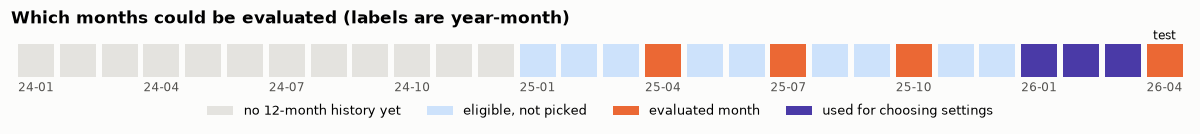

In [12]:
TRAIN_C, EVAL_C, CHOICE_C, ELIGIBLE_C, EARLY_C = '#2a78d6', '#eb6834', '#4a3aa7', '#cde2fb', LIGHT_GRAY
months_all = sorted(clean_df['CloseMonth'].unique())
pos = {m: i for i, m in enumerate(months_all)}
choice_months = ['2026-01', '2026-02', '2026-03']


def month_axis(ax):
    ax.set_xticks(range(len(months_all)), [m[2:4] + '-' + m[5:] if m.endswith(('-01', '-04', '-07', '-10')) else ''
                                           for m in months_all], fontsize=8)
    ax.set_xlim(-0.6, len(months_all) - 0.4)
    ax.grid(False)
    for s in ['left', 'bottom']:
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)


fig, ax = plt.subplots(figsize=(11, 1.6))
for m in months_all:
    i = pos[m]
    if i < N_MONTHS:
        color, label = EARLY_C, 'no 12-month history yet'
    elif m == TEST_MONTH or m in BACKTEST_MONTHS:
        color, label = EVAL_C, 'evaluated month'
    elif m in choice_months:
        color, label = CHOICE_C, 'used for choosing settings'
    else:
        color, label = ELIGIBLE_C, 'eligible, not picked'
    ax.bar(i, 1, width=0.86, color=color, label=label)
    if m == TEST_MONTH:
        ax.text(i, 1.05, 'test', ha='center', va='bottom', fontsize=8)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend([uniq[k] for k in ['no 12-month history yet', 'eligible, not picked', 'evaluated month', 'used for choosing settings']],
          ['no 12-month history yet', 'eligible, not picked', 'evaluated month', 'used for choosing settings'],
          loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False, fontsize=8.5)
ax.set_yticks([])
ax.set_ylim(0, 1.35)
month_axis(ax)
ax.set_title('Which months could be evaluated (labels are year-month)')
plt.tight_layout()
save_fig('04_month_roles')
plt.show()

**Each evaluated month gets its own model.** Each run trains a fresh model on the 12 months before its evaluated month, so no model is scored on a month it trained on. A month evaluated in an early run can still be a training month in a later run (hatched cells below); that is a different model, scored on a later month.

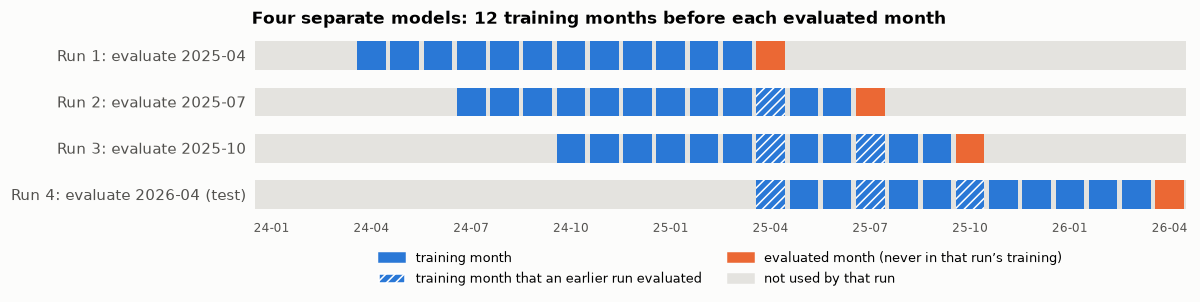

In [13]:
fig, ax = plt.subplots(figsize=(11, 2.9))
for row, eval_month in enumerate(reversed(BACKTEST_MONTHS)):
    run = len(BACKTEST_MONTHS) - row
    e = pos[eval_month]
    ax.barh(row, len(months_all), left=-0.5, height=0.62, color=LIGHT_GRAY, zorder=0)
    for m in months_all[e - N_MONTHS:e]:
        earlier_eval = m in BACKTEST_MONTHS
        ax.barh(row, 0.86, left=pos[m] - 0.43, height=0.62, color=TRAIN_C,
                hatch='////' if earlier_eval else None, edgecolor='#ffffff' if earlier_eval else TRAIN_C, linewidth=0)
    ax.barh(row, 0.86, left=e - 0.43, height=0.62, color=EVAL_C)
ax.set_yticks(range(len(BACKTEST_MONTHS)),
              [f'Run {len(BACKTEST_MONTHS) - r}: evaluate {m}' + (' (test)' if m == TEST_MONTH else '')
               for r, m in enumerate(reversed(BACKTEST_MONTHS))])
month_axis(ax)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=TRAIN_C, label='training month'),
                   Patch(facecolor=TRAIN_C, hatch='////', edgecolor='#ffffff', label='training month that an earlier run evaluated'),
                   Patch(color=EVAL_C, label='evaluated month (never in that run’s training)'),
                   Patch(color=LIGHT_GRAY, label='not used by that run')],
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=8.5)
ax.set_title('Four separate models: 12 training months before each evaluated month')
plt.tight_layout()
save_fig('04_evaluation_timeline')
plt.show()

**Check 2: how much the test-month difference could vary by chance.** The 12,268 test homes are a sample; with a different set of homes the difference between two models would come out somewhat differently. To estimate how much, the test homes are resampled with replacement 2,000 times (a *paired bootstrap*: both models are scored on the same resampled homes) and the difference in MdAPE is recomputed each time. The middle 95% of these differences gives a 95% interval. If the interval excludes zero by a wide margin, the improvement is very unlikely to be a fluke of which homes sold in April.

In [14]:
y_test = test_final[prep.TARGET].to_numpy()
pairs = [('Linear regression', 'Decision tree'), ('Linear regression', 'Random forest'), ('Decision tree', 'Random forest')]
boot = pd.DataFrame([{'comparison': f'{a} minus {b}', **mdl.bootstrap_mdape_difference(y_test, test_preds[a], test_preds[b])}
                     for a, b in pairs]).set_index('comparison')
boot.columns = ['MdAPE difference (points)', '95% interval low', '95% interval high']
boot.round(2)

,MdAPE difference (points),95% interval low,95% interval high
comparison,,,
Linear regression minus Decision tree,1.57,1.27,1.85
Linear regression minus Random forest,3.62,3.37,3.88
Decision tree minus Random forest,2.05,1.82,2.31


## 6. Where the improvement comes from

Week 4 found the baseline's clearest weakness in the most expensive homes, predicted too low by a median of 11%, and suggested a reason: a linear model adds up a separate effect for each input, so it cannot express that a combination (a large house in an expensive ZIP code) is worth more than its parts. Trees can express such combinations. If that explanation is right, the tree models should gain the most in the expensive price band. The test homes are again split into five groups of nearly equal size by sale price.

In [15]:
bands = pd.qcut(y_test, 5, labels=[f'Q{i}' for i in range(1, 6)])
edges = pd.Series(y_test).groupby(bands, observed=True).agg(['min', 'max'])
band_tables = {n: mdl.error_by_group(y_test, p, bands) for n, p in test_preds.items()}

by_band = pd.DataFrame({'price range': [f'{money(a)} to {money(b)}' for a, b in edges.to_numpy()]}, index=edges.index)
for n, t in band_tables.items():
    by_band[f'{n}: MdAPE'] = t['MdAPE'].round(2)
for n, t in band_tables.items():
    by_band[f'{n}: signed'] = t['median_signed_error'].round(2)
by_band

,price range,Linear regression: MdAPE,Decision tree: MdAPE,Random forest: MdAPE,Linear regression: signed,Decision tree: signed,Random forest: signed
Q1,$185K to $575K,10.40,9.10,6.69,3.23,2.43,1.96
Q2,$575K to $800K,10.05,7.27,5.76,1.18,0.04,-0.17
Q3,$802K to $1.1M,9.97,8.79,6.67,1.25,-1.73,-1.25
Q4,$1.1M to $1.7M,11.74,11.41,8.83,-3.33,-3.67,-3.56
Q5,$1.7M to $8.6M,16.03,14.60,12.45,-11.34,-7.98,-8.16


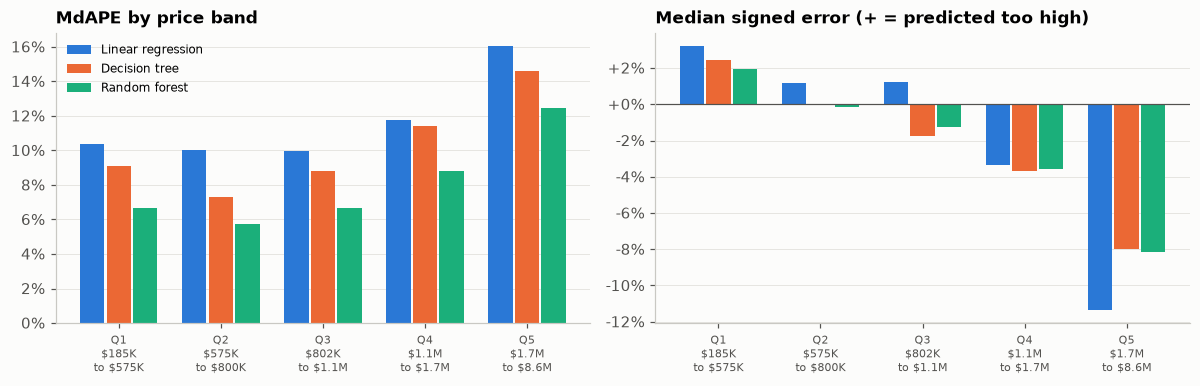

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
width = 0.26
x = np.arange(5)
ranges = by_band['price range'].str.replace('$', r'\$').str.replace(' to ', '\nto ')
for k, name in enumerate(MODELS):
    t = band_tables[name]
    axes[0].bar(x + (k - 1) * width, t['MdAPE'], width=width * 0.92, color=COLORS[name], label=name)
    axes[1].bar(x + (k - 1) * width, t['median_signed_error'], width=width * 0.92, color=COLORS[name], label=name)
for ax in axes:
    ax.set_xticks(x, [f'{q}\n{r}' for q, r in zip(by_band.index, ranges)], fontsize=7.5)
    ax.grid(axis='x', visible=False)
axes[0].set_title('MdAPE by price band')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[0].legend(frameon=False, fontsize=8)
axes[1].axhline(0, color='#52514e', lw=0.8)
axes[1].set_title('Median signed error (+ = predicted too high)')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:+.0f}%'))
plt.tight_layout()
save_fig('04_error_by_band')
plt.show()

In [17]:
gain = pd.DataFrame({
    'baseline MdAPE': band_tables['Linear regression']['MdAPE'],
    'forest MdAPE': band_tables['Random forest']['MdAPE'],
})
gain['improvement (points)'] = gain['baseline MdAPE'] - gain['forest MdAPE']
gain['improvement (% of baseline error)'] = 100 * gain['improvement (points)'] / gain['baseline MdAPE']
gain.round(2)

,baseline MdAPE,forest MdAPE,improvement (points),improvement (% of baseline error)
group,,,,
Q1,10.40,6.69,3.71,35.64
Q2,10.05,5.76,4.28,42.64
Q3,9.97,6.67,3.30,33.06
Q4,11.74,8.83,2.90,24.75
Q5,16.03,12.45,3.57,22.29


## 7. What the random forest relies on

A forest has no coefficients to read. Instead, *permutation importance* measures how much each input matters: the values of one input are shuffled randomly across the homes of the validation month, which breaks that input's link with price while leaving everything else unchanged, and the rise in MdAPE is recorded. The larger the rise, the more the model depends on that input. Each input is shuffled 5 times and the results averaged. The importance is computed for the 17 original inputs (latitude and longitude separately), on the forest trained on the settings split, so the test month is not used.

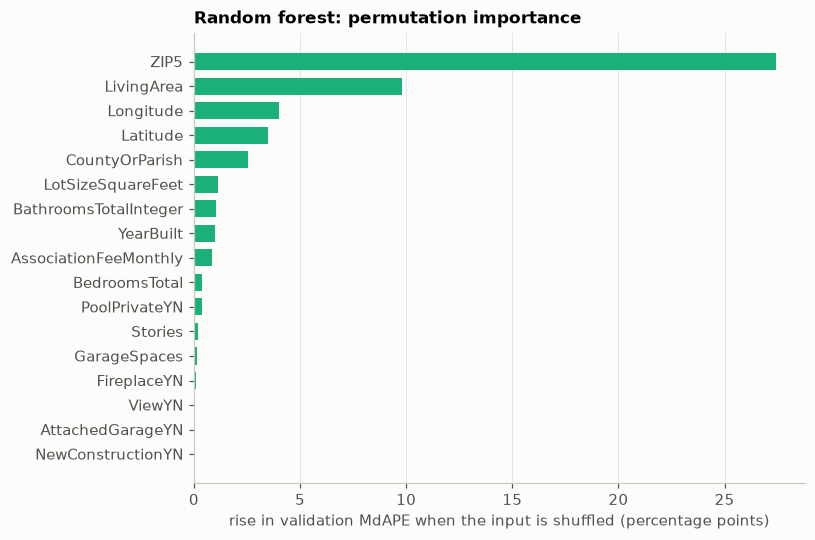

,MdAPE rise (points)
ZIP5,27.40
LivingArea,9.78
Longitude,4.03
Latitude,3.51
CountyOrParish,2.54
LotSizeSquareFeet,1.13
BathroomsTotalInteger,1.02
YearBuilt,0.98


In [18]:
forest_tune = mdl.price_model(MODELS['Random forest']()).fit(train_tune[prep.FEATURES], train_tune[prep.TARGET])


def neg_mdape(y_true, y_pred):
    return -prep.regression_metrics(y_true, y_pred)['MdAPE']


imp = permutation_importance(forest_tune, val_tune[prep.FEATURES], val_tune[prep.TARGET],
                             scoring=make_scorer(neg_mdape), n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=prep.FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(importance.index, importance.values, color=COLORS['Random forest'], height=0.7)
ax.set_xlabel('rise in validation MdAPE when the input is shuffled (percentage points)')
ax.set_title('Random forest: permutation importance')
ax.grid(axis='y', visible=False)
plt.tight_layout()
save_fig('04_rf_importance')
plt.show()
importance.sort_values(ascending=False).round(2).head(8).to_frame('MdAPE rise (points)')

## 8. Strengths and weaknesses

The table below collects the evidence from this notebook. A few measurements behind it come first: how many different prices each model can predict, how far it can predict beyond the training prices, and how large it is.

In [19]:
dt_inner = final_models['Decision tree'].regressor_.named_steps['model']
rf_inner = final_models['Random forest'].regressor_.named_steps['model']
train_max = train_final[prep.TARGET].max()
facts = pd.DataFrame({
    'distinct predicted prices (test month)': {n: len(np.unique(np.round(p, 2))) for n, p in test_preds.items()},
    'highest prediction': {n: money(p.max()) for n, p in test_preds.items()},
    'highest prediction / highest training price': {n: f'{p.max() / train_max:.2f}' for n, p in test_preds.items()},
})
print(f'Decision tree: {dt_inner.get_n_leaves():,} leaves, depth {dt_inner.get_depth()}')
print(f'Random forest: {len(rf_inner.estimators_)} trees, '
      f'{sum(t.tree_.node_count for t in rf_inner.estimators_):,} nodes in total')
print(f'Highest training price: {money(train_max)}')
facts

Decision tree: 9,081 leaves, depth 20
Random forest: 300 trees, 47,900,796 nodes in total
Highest training price: $8.6M


,distinct predicted prices (test month),highest prediction,highest prediction / highest training price
Linear regression,12264,$8.4M,0.98
Decision tree,6165,$7.8M,0.90
Random forest,12260,$6.8M,0.79


| | Linear regression (Week 4 baseline) | Decision tree | Random forest |
|---|---|---|---|
| **Accuracy** | Weakest of the three | Clearly better than the baseline | Best, by a wide margin |
| **Overfitting** | Almost none: training and test errors are nearly equal | Fits training homes noticeably better than test homes | Fits training homes far better than test homes, yet still predicts new homes best |
| **Combinations of inputs** | Cannot express them; adds separate effects | Can, through successive questions | Can, and averages out the noise of single trees |
| **Shape of predictions** | Smooth: any value | Steps: one price per leaf | Many small steps averaged into a near-smooth surface |
| **Highest prices** | Can in principle predict above the highest training price; its highest test prediction is 0.98 times the highest training price | Cannot exceed the highest training price (a leaf average never does); highest test prediction 0.90 times it | Cannot exceed it either, and averaging pulls extreme predictions further toward the middle: highest test prediction only 0.79 times it |
| **Interpretation** | Each coefficient is a percentage effect | The top few questions can be read directly | Needs indirect tools such as permutation importance |
| **Speed and size** | Fits in under a second; tiny | Fits in about a second; small | Fits in seconds on 24 cores; hundreds of trees with millions of nodes |
| **Settings to tune** | None | Depth and leaf size, sensitive | Several, but results are fairly flat near the best |

Two points deserve emphasis. First, the forest's large gap between training and test error is expected and harmless: each tree memorizes its bootstrap sample, but averaging many such trees still gives the best predictions on new homes. What matters is the test error, not the gap. Second, tree models cannot predict a price higher than the highest training price, and the forest's averaging pulls its most extreme predictions toward the middle: its highest test-month prediction is $6.8M, against a highest training price of $8.6M. This is one reason the most expensive homes remain the hardest to predict (Section 6), and it means the forest cannot follow a market that moves above its training range.

## 9. Saved results

Three tables are written to `results/` (scores only, no property data): the final test-month comparison with the earlier-month results, and the two settings searches.

In [20]:
comparison = backtest.copy()
comparison['evaluation'] = np.where(comparison['eval_month'] == TEST_MONTH, 'test (final result)', 'earlier month (stability)')
comparison = comparison[['model', 'evaluation', 'eval_month', 'train_months', 'train_rows', 'eval_rows', 'R2', 'MAPE', 'MdAPE', 'MAE']]
for name in MODELS:
    t = comparison[(comparison['model'] == name) & (comparison['eval_month'] == TEST_MONTH)]
    assert np.isclose(t['MdAPE'].item(), final.loc[name, 'MdAPE'])
comparison.to_csv(RESULTS_DIR / '04_model_comparison.csv', index=False, float_format='%.6f')
dt_grid.to_csv(RESULTS_DIR / '04_tuning_decision_tree.csv', index=False, float_format='%.6f')
rf_grid.to_csv(RESULTS_DIR / '04_tuning_random_forest.csv', index=False, float_format='%.6f')
print('Saved: 04_model_comparison.csv, 04_tuning_decision_tree.csv, 04_tuning_random_forest.csv')

Saved: 04_model_comparison.csv, 04_tuning_decision_tree.csv, 04_tuning_random_forest.csv


## 10. Summary and next steps

**Test month (April 2026), one evaluation per model:**

| Model | R² | MAPE | MdAPE | MAE | Homes within 10% |
|---|---:|---:|---:|---:|---:|
| Linear regression (baseline) | 0.820 | 15.17% | 11.38% | $207,051 | 44.7% |
| Decision tree | 0.844 | 14.19% | 9.81% | $194,300 | 50.7% |
| **Random forest** | **0.885** | **11.42%** | **7.76%** | **$159,355** | **59.8%** |

**Chosen settings (on the March 2026 validation month).** Decision tree: maximum depth 20, minimum leaf size 10 (validation MdAPE 9.55%). Random forest: 300 trees, one third of the input columns per split, minimum leaf size 1 (validation MdAPE 7.68%); 500 trees improved validation MdAPE by only 0.03 points.

**The improvement is real.**
- The forest beats the baseline by 3.62 MdAPE points on the test month; the 95% bootstrap interval is 3.37 to 3.88 points. The tree beats the baseline by 1.57 points (1.27 to 1.85), and the forest beats the tree by 2.05 points (1.82 to 2.31).
- The ranking is the same at all four evaluated months. The forest's MdAPE stays between 7.39% and 7.76%, about 3.4 to 3.6 points below the baseline each month, far more than the baseline's 0.55-point month-to-month range.

**Where it comes from.** The forest improves every price band, by 2.9 to 4.3 MdAPE points. Relative to the baseline's error, the gain is largest in the middle bands (43% lower error in Q2) and smallest for the most expensive homes (25% in Q4, 22% in Q5). The most expensive fifth is still predicted too low, though less so (median signed error −8.2% against −11.3%). The Week 4 explanation is therefore only partly supported: being able to represent combinations of inputs helps expensive homes, but it helps mid-priced homes even more, and the forest's averaging, which caps its highest prediction at $6.8M, keeps the top band hard.

**What the forest relies on.** Shuffling the ZIP code raises validation MdAPE by 27.4 points, living area by 9.8, longitude by 4.0, latitude by 3.5 and county by 2.5. The yes/no amenity flags barely matter once location and size are known.

**Behavior.** The single tree overfits visibly (MdAPE 7.39% on its training homes against 9.81% on the test month), and its predictions come in steps, one price per leaf. The forest fits its training homes much more closely still (3.34%), yet predicts new homes best, because averaging 300 deep trees cancels most of their individual noise. It costs about 6 seconds to train on 24 cores and has 47.9 million tree nodes.

**Next steps (Week 6, feature engineering)**
1. Add engineered features: age of the home at sale, bedroom-to-bathroom ratio, month of sale (sine and cosine) and the school-district layer.
2. Retrain the three models with the new features and compare old against new feature sets in one table.
3. Recheck the 12-month training window, since time-of-sale features make older months more useful.
4. Watch the most expensive fifth, where every model still predicts too low.